# DocSentry — 03. Data Preprocessing & Leakage Prevention Pipeline

## Executive Overview
This notebook implements the foundational preprocessing, temporal splitting, and feature normalization pipeline for **DocSentry**: an explainable, uncertainty-aware PDF malware detector using static features from the **EMBER2024** benchmark subset.

### Strict Methodological Principles
1. **Zero Data Leakage**: All dimensionality reductions, feature filtering, and scaling statistics (`StandardScaler`) are computed and fitted **strictly on the training split** (the first 42 weeks of 2023–2024). Validation (weeks 42–51) and test (12 evaluation weeks) sets are transformed using frozen parameters.
2. **Empirical Verification Over Narrative**: Every assertion regarding class differences, feature distributions, constant features, and temporal drift is verified through explicit code execution and reproducible computations.
3. **Temporal Realism**: Preserves the chronological order of weekly collection batches to simulate real-world production deployment and evaluate temporal concept drift.
4. **Dual Modeling Pipeline**:
   - **Tree Pipeline (`_tree`)**: Preserves raw, unscaled feature values for non-parametric and gradient-boosted tree architectures (Random Forest, XGBoost, LightGBM).
   - **Linear Pipeline (`_linear`)**: Compresses extreme right-skewed count/size features via $\log(1+x)$ and applies z-score standardization (`StandardScaler`) for gradient-based or regularized linear models (Logistic Regression, SVM).

## 0. Setup and Environment Verification
Import required mathematical, statistical, machine learning, and visualization libraries. We enforce explicit random seeds and verify CPU execution settings.

In [1]:
import os
import re
import json
import time
import joblib
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import polars as pl
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting configurations
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

FIGURES_DIR = Path('../reports/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR = Path('../data/processed')
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

from thrember.features import (
    GeneralFileInfo,
    ByteHistogram,
    ByteEntropyHistogram,
    StringExtractor
)

print(f"Setup complete. Polars v{pl.__version__}, NumPy v{np.__version__}, Pandas v{pd.__version__}.")

Setup complete. Polars v2.1.0, NumPy v2.5.5, Pandas v3.1.1.


---
# PART A: Verify the EDA Findings (Read-Only Audit)

In this section, we empirically verify the findings established during exploratory data analysis (EDA):
1. Reconcile the discrepancy between 76 vs. 77 regex patterns in `thrember`'s `StringExtractor`.
2. Compute actual per-class median file size, mean entropy, and mean string count (`numstrings`).
3. Compute Cohen's $d$ effect sizes across all candidate features and tabulate the top 25 separating features.
4. Distinguish truly constant features (`nunique == 1`) from low-variance histogram bins ($< 10^{-8}$), establishing whether aggressive low-variance filtering is methodologically sound.

### 1. Regex Indicator Reconciliation: Resolving 76 vs. 77
We inspect the instantiated `StringExtractor` from `thrember` to catalog all regex patterns, identify PDF-specific keywords, and explain the exact architectural reason for the 76 vs. 77 discrepancy.

In [2]:
extractor_strings = StringExtractor()
regex_dict = extractor_strings._regexes
regex_names = sorted(regex_dict.keys())

# PDF-specific keywords vs. Generic / Unix / Script keywords
pdf_specific_keywords = {'/URI', '/FlateDecode', '/EmbeddedFile'}
unix_keywords = {'/bin/', '/dev/', '/proc/', '/tmp/', '/usr/'}

regex_catalog = []
for idx, name in enumerate(regex_names, 1):
    category = "PDF Keyword" if name in pdf_specific_keywords else ("Unix System Path" if name in unix_keywords else "Generic Indicator")
    pattern_repr = regex_dict[name].pattern
    regex_catalog.append({
        'Index': idx,
        'Feature Name': f"strings_regex_{name}",
        'Category': category,
        'Pattern': pattern_repr[:40] + ('...' if len(pattern_repr) > 40 else '')
    })

df_regex = pd.DataFrame(regex_catalog)

print("=" * 80)
print(f"STRING EXTRACTOR REGEX RECONCILIATION AUDIT (Total Patterns: {len(regex_names)})")
print("=" * 80)
print(f"Total regexes identified in StringExtractor._regexes: {len(regex_names)}")
print(f"Explicit PDF-specific keywords identified: {len(pdf_specific_keywords)} -> {sorted(pdf_specific_keywords)}")
print(f"Unix root path patterns identified: {len(unix_keywords)} -> {sorted(unix_keywords)}")
print(f"Generic indicators: {len(regex_names) - len(pdf_specific_keywords) - len(unix_keywords)}")

print("\nExplanation of 76 vs 77 in EMBER2024 Source Code:")
print("-" * 80)
print("In thrember/features.py, StringExtractor specifies: self.dim = 5 + 96 + 76 = 177.")
print("The author assumed: 5 scalar metrics + 96 printable dist bins + 76 regexes = 177 features.")
print("In reality:")
print("  - Scalar metrics implemented = 4 (numstrings, avlength, printables, entropy)")
print("  - Printable distribution bins = 96")
print("  - Compiled regex patterns in self._regexes = 77")
print(f"  - Actual sum: 4 + 96 + 77 = {4 + 96 + 77} features.")
print("The off-by-one errors in scalar count (4 vs 5) and regex count (77 vs 76) cancelled out perfectly.")
print("Thus, 77 is the TRUE, EXACT number of regex features in EMBER2024 PDF feature representation.")

print("\nSample of Regex Indicator Catalog (First 15 patterns):")
display(df_regex.head(15))

STRING EXTRACTOR REGEX RECONCILIATION AUDIT (Total Patterns: 77)
Total regexes identified in StringExtractor._regexes: 77
Explicit PDF-specific keywords identified: 3 -> ['/EmbeddedFile', '/FlateDecode', '/URI']
Unix root path patterns identified: 5 -> ['/bin/', '/dev/', '/proc/', '/tmp/', '/usr/']
Generic indicators: 69

Explanation of 76 vs 77 in EMBER2024 Source Code:
--------------------------------------------------------------------------------
In thrember/features.py, StringExtractor specifies: self.dim = 5 + 96 + 76 = 177.
The author assumed: 5 scalar metrics + 96 printable dist bins + 76 regexes = 177 features.
In reality:
  - Scalar metrics implemented = 4 (numstrings, avlength, printables, entropy)
  - Printable distribution bins = 96
  - Compiled regex patterns in self._regexes = 77
  - Actual sum: 4 + 96 + 77 = 177 features.
The off-by-one errors in scalar count (4 vs 5) and regex count (77 vs 76) cancelled out perfectly.
Thus, 77 is the TRUE, EXACT number of regex feature

,Index,Feature Name,Category,Pattern
0,1,strings_regex_.click(,Generic Indicator,.click
1,2,strings_regex_/EmbeddedFile,PDF Keyword,/EmbeddedFile
2,3,strings_regex_/FlateDecode,PDF Keyword,/FlateDecode
3,4,strings_regex_/URI,PDF Keyword,/URI
4,5,strings_regex_/bin/,Unix System Path,/bin/
5,6,strings_regex_/dev/,Unix System Path,/dev/
6,7,strings_regex_/proc/,Unix System Path,/proc/
7,8,strings_regex_/tmp/,Unix System Path,/tmp/
8,9,strings_regex_/usr/,Unix System Path,/usr/
9,10,strings_regex_<script,Generic Indicator,<script


### 2. Empirical Verification of Class Distributions
We compute per-class summary statistics directly from the deduplicated training dataset (`dedup_train.parquet`, 52,000 samples) and the 42-week training split (42,000 samples) without reliance on narrative estimates.

In [3]:
df_train_dedup = pl.read_parquet('../data/processed/dedup_train.parquet')
df_test_dedup = pl.read_parquet('../data/processed/dedup_test.parquet')

# Extract general and string attributes for 52,000 dedup train
records_52k = df_train_dedup.to_dicts()

b_sizes = [r['general']['size'] for r in records_52k if r['label'] == 0]
m_sizes = [r['general']['size'] for r in records_52k if r['label'] == 1]

b_entropy = [r['general']['entropy'] for r in records_52k if r['label'] == 0]
m_entropy = [r['general']['entropy'] for r in records_52k if r['label'] == 1]

b_numstrings = [r['strings']['numstrings'] for r in records_52k if r['label'] == 0]
m_numstrings = [r['strings']['numstrings'] for r in records_52k if r['label'] == 1]

# Extract for 42-week train split (week_id < 42)
records_42k = [r for r in records_52k if r['week_id'] < 42]
b_sizes_42k = [r['general']['size'] for r in records_42k if r['label'] == 0]
m_sizes_42k = [r['general']['size'] for r in records_42k if r['label'] == 1]

b_entropy_42k = [r['general']['entropy'] for r in records_42k if r['label'] == 0]
m_entropy_42k = [r['general']['entropy'] for r in records_42k if r['label'] == 1]

b_numstrings_42k = [r['strings']['numstrings'] for r in records_42k if r['label'] == 0]
m_numstrings_42k = [r['strings']['numstrings'] for r in records_42k if r['label'] == 1]

stats_summary = pd.DataFrame([
    {
        'Dataset': 'Full Dedup Train (52k)',
        'Metric': 'Median File Size (bytes)',
        'Benign (Class 0)': f"{np.median(b_sizes):,.1f}",
        'Malicious (Class 1)': f"{np.median(m_sizes):,.1f}",
        'Ratio / Difference': f"{np.median(b_sizes) / np.median(m_sizes):.2f}x benign larger"
    },
    {
        'Dataset': 'Full Dedup Train (52k)',
        'Metric': 'Mean Shannon Entropy',
        'Benign (Class 0)': f"{np.mean(b_entropy):.4f}",
        'Malicious (Class 1)': f"{np.mean(m_entropy):.4f}",
        'Ratio / Difference': f"{np.mean(m_entropy) - np.mean(b_entropy):+.4f} (malicious higher)"
    },
    {
        'Dataset': 'Full Dedup Train (52k)',
        'Metric': 'Mean String Count (numstrings)',
        'Benign (Class 0)': f"{np.mean(b_numstrings):,.2f}",
        'Malicious (Class 1)': f"{np.mean(m_numstrings):,.2f}",
        'Ratio / Difference': f"{np.mean(b_numstrings) / np.mean(m_numstrings):.2f}x benign richer"
    },
    {
        'Dataset': 'Train Split (42k, Weeks 0-41)',
        'Metric': 'Median File Size (bytes)',
        'Benign (Class 0)': f"{np.median(b_sizes_42k):,.1f}",
        'Malicious (Class 1)': f"{np.median(m_sizes_42k):,.1f}",
        'Ratio / Difference': f"{np.median(b_sizes_42k) / np.median(m_sizes_42k):.2f}x benign larger"
    },
    {
        'Dataset': 'Train Split (42k, Weeks 0-41)',
        'Metric': 'Mean Shannon Entropy',
        'Benign (Class 0)': f"{np.mean(b_entropy_42k):.4f}",
        'Malicious (Class 1)': f"{np.mean(m_entropy_42k):.4f}",
        'Ratio / Difference': f"{np.mean(m_entropy_42k) - np.mean(b_entropy_42k):+.4f} (malicious higher)"
    },
    {
        'Dataset': 'Train Split (42k, Weeks 0-41)',
        'Metric': 'Mean String Count (numstrings)',
        'Benign (Class 0)': f"{np.mean(b_numstrings_42k):,.2f}",
        'Malicious (Class 1)': f"{np.mean(m_numstrings_42k):,.2f}",
        'Ratio / Difference': f"{np.mean(b_numstrings_42k) / np.mean(m_numstrings_42k):.2f}x benign richer"
    }
])

print("=" * 90)
print("EMPIRICAL PER-CLASS SUMMARY STATISTICS")
print("=" * 90)
display(stats_summary)

EMPIRICAL PER-CLASS SUMMARY STATISTICS


,Dataset,Metric,Benign (Class 0),Malicious (Class 1),Ratio / Difference
0,Full Dedup Train (52k),Median File Size (bytes),"463,940.5","93,821.5",4.94x benign larger
1,Full Dedup Train (52k),Mean Shannon Entropy,7.6988,7.7653,+0.0665 (malicious higher)
2,Full Dedup Train (52k),Mean String Count (numstrings),"15,254.20","1,102.44",13.84x benign richer
3,"Train Split (42k, Weeks 0-41)",Median File Size (bytes),"416,198.5","92,591.5",4.49x benign larger
4,"Train Split (42k, Weeks 0-41)",Mean Shannon Entropy,7.6652,7.7608,+0.0956 (malicious higher)
5,"Train Split (42k, Weeks 0-41)",Mean String Count (numstrings),"15,311.01","1,085.60",14.10x benign richer


### 3. Class Separation Analysis: Top 25 Features by |Cohen's d|
We vectorize the raw feature families for the training split (42,000 samples) and compute the parametric effect size Cohen's $d$:
$$d = \frac{\mu_{\text{malicious}} - \mu_{\text{benign}}}{s_{\text{pooled}}}, \quad s_{\text{pooled}} = \sqrt{\frac{(n_1 - 1)s_1^2 + (n_2 - 1)s_2^2}{n_1 + n_2 - 2}}$$
This identifies the strongest linear discriminators in the static feature space.

In [4]:
extractor_general = GeneralFileInfo()
extractor_bytehist = ByteHistogram()
extractor_entropy = ByteEntropyHistogram()
extractor_strings = StringExtractor()

general_feature_names = [
    'general_size', 'general_entropy', 'general_is_pe',
    'general_start_byte_0', 'general_start_byte_1', 'general_start_byte_2', 'general_start_byte_3'
]

raw_feature_names_696 = []
raw_feature_names_696.extend(general_feature_names)
raw_feature_names_696.extend([f"byte_hist_{i:03d}" for i in range(256)])
raw_feature_names_696.extend([f"byte_entropy_{r:02d}_{c:02d}" for r in range(16) for c in range(16)])
raw_feature_names_696.append("strings_numstrings")
raw_feature_names_696.append("strings_avlength")
raw_feature_names_696.append("strings_printables")
raw_feature_names_696.extend([f"strings_printabledist_{i:02d}" for i in range(96)])
raw_feature_names_696.append("strings_entropy")
raw_feature_names_696.extend([f"strings_regex_{k}" for k in sorted(extractor_strings._regexes.keys())])

assert len(raw_feature_names_696) == 696

def vectorize_subset(records):
    N = len(records)
    X = np.empty((N, 696), dtype=np.float32)
    y = np.empty(N, dtype=np.int32)
    for i, r in enumerate(records):
        y[i] = r['label']
        X[i, :7] = extractor_general.process_raw_features(r['general'])
        X[i, 7:263] = extractor_bytehist.process_raw_features(r['histogram'])
        X[i, 263:519] = extractor_entropy.process_raw_features(r['byteentropy'])
        sc = r['strings'].get('string_counts', {}) if isinstance(r['strings'], dict) else {}
        str_counts = np.zeros(len(extractor_strings.regex_idxs), dtype=np.float32)
        if isinstance(sc, dict):
            for k, v in sc.items():
                if k in extractor_strings.regex_idxs and v is not None:
                    str_counts[extractor_strings.regex_idxs[k]] = float(v)
        hist_div = float(r['strings']['printables']) if r['strings']['printables'] > 0 else 1.0
        pdist = np.asarray(r['strings']['printabledist'], dtype=np.float32) / hist_div
        X[i, 519:] = np.hstack([
            r['strings']['numstrings'], r['strings']['avlength'], r['strings']['printables'],
            pdist, r['strings']['entropy'], str_counts
        ])
    return X, y

print(f"Vectorizing 42-week training split (42,000 samples)...")
t0 = time.time()
X_tr_42k, y_tr_42k = vectorize_subset(records_42k)
print(f"Vectorized in {time.time()-t0:.2f}s | Shape: {X_tr_42k.shape}")

# Compute Cohen's d
b_mask = (y_tr_42k == 0)
m_mask = (y_tr_42k == 1)
n_b, n_m = b_mask.sum(), m_mask.sum()

mean_b = X_tr_42k[b_mask].mean(axis=0)
mean_m = X_tr_42k[m_mask].mean(axis=0)
var_b = X_tr_42k[b_mask].var(axis=0, ddof=1)
var_m = X_tr_42k[m_mask].var(axis=0, ddof=1)

pooled_sd = np.sqrt(((n_b - 1) * var_b + (n_m - 1) * var_m) / (n_b + n_m - 2))
with np.errstate(divide='ignore', invalid='ignore'):
    cohens_d = (mean_m - mean_b) / pooled_sd
cohens_d = np.nan_to_num(cohens_d, nan=0.0)

abs_cohens_d = np.abs(cohens_d)
top_25_indices = np.argsort(abs_cohens_d)[::-1][:25]

df_top_25_d = pd.DataFrame({
    'Rank': range(1, 26),
    'Feature Name': [raw_feature_names_696[i] for i in top_25_indices],
    "Cohen's d": cohens_d[top_25_indices],
    "|Cohen's d|": abs_cohens_d[top_25_indices],
    'Family': [
        'General' if i < 7 else ('ByteHist' if i < 263 else ('ByteEntropy' if i < 519 else 'Strings'))
        for i in top_25_indices
    ]
})

print("=" * 85)
print("TOP 25 SEPARATING FEATURES BY ABSOLUTE COHEN'S D (TRAIN SPLIT)")
print("=" * 85)
display(df_top_25_d)

Vectorizing 42-week training split (42,000 samples)...


Vectorized in 7.35s | Shape: (42000, 696)


TOP 25 SEPARATING FEATURES BY ABSOLUTE COHEN'S D (TRAIN SPLIT)


,Rank,Feature Name,Cohen's d,|Cohen's d|,Family
0,1,strings_printabledist_80,1.519261,1.519261,Strings
1,2,strings_printabledist_68,1.349595,1.349595,Strings
2,3,strings_printabledist_79,1.175833,1.175833,Strings
3,4,strings_printabledist_78,1.146280,1.146280,Strings
4,5,strings_printabledist_15,1.090216,1.090216,Strings
5,6,strings_printabledist_69,1.028758,1.028758,Strings
6,7,strings_printabledist_73,1.012117,1.012117,Strings
7,8,strings_printabledist_37,-0.995878,0.995878,Strings
8,9,byte_hist_121,0.946252,0.946252,ByteHist
9,10,strings_printabledist_56,-0.941738,0.941738,Strings


### 4. Constant vs. Low-Variance Audit: Was the 66-Feature Drop Justified?
We audit features exhibiting zero or near-zero variance. Specifically, we test whether dropping features solely on a variance threshold ($< 10^{-8}$) inappropriately removes informative histogram bins with sparse positive probabilities.

In [5]:
# 1. Truly constant features (nunique == 1, min == max)
truly_constant_mask = (X_tr_42k.min(axis=0) == X_tr_42k.max(axis=0))
truly_constant_idx = np.where(truly_constant_mask)[0]

# 2. Low-variance threshold (< 1e-8)
variances_42k = X_tr_42k.var(axis=0)
low_var_mask = (variances_42k < 1e-8)
low_var_idx = np.where(low_var_mask)[0]

# 3. Analyze non-zero activation frequency for low-variance features
nonzero_fractions = (X_tr_42k != 0).mean(axis=0)

histogram_active_count = 0
for idx in low_var_idx:
    fname = raw_feature_names_696[idx]
    is_hist = ('byte_hist' in fname or 'byte_entropy' in fname)
    if is_hist and nonzero_fractions[idx] >= 0.01:
        histogram_active_count += 1

print("=" * 85)
print("CONSTANT VS. LOW-VARIANCE STATISTICAL AUDIT")
print("=" * 85)
print(f"1. Truly constant features (nunique == 1, var == 0): {len(truly_constant_idx)}")
print(f"   - general_is_pe: {raw_feature_names_696[2]} (always 0.0 for PDFs)")
print(f"   - Constant string regex indicators: {len(truly_constant_idx) - 1}")

print(f"\n2. Features with variance < 1e-8: {len(low_var_idx)}")
print(f"   - Of these {len(low_var_idx)} features, {len(truly_constant_idx)} are truly constant.")
print(f"   - The remaining {len(low_var_idx) - len(truly_constant_idx)} features have variance between 0 and 1e-8.")
print(f"   - Byte / ByteEntropy histogram bins active in >= 1% of files: {histogram_active_count} of {len(low_var_idx)}")

print("\n3. Methodological Assessment:")
print("-" * 85)
print("JUSTIFICATION: The previously suggested blind drop of 66 features with variance < 1e-8")
print("WAS NOT JUSTIFIED. Normalized histogram and joint byte-entropy probabilities naturally")
print("take small fractional values (e.g., 1e-4) whose empirical variance is below 1e-8.")
print(f"Yet {histogram_active_count} of these features represent valid byte distributions active in thousands")
print("of samples. Blindly dropping them discards genuine structural PDF content.")
print("CONCLUSION: Only drop truly constant features (nunique == 1) in the training split.")

CONSTANT VS. LOW-VARIANCE STATISTICAL AUDIT
1. Truly constant features (nunique == 1, var == 0): 38
   - general_is_pe: general_is_pe (always 0.0 for PDFs)
   - Constant string regex indicators: 37

2. Features with variance < 1e-8: 67
   - Of these 67 features, 38 are truly constant.
   - The remaining 29 features have variance between 0 and 1e-8.
   - Byte / ByteEntropy histogram bins active in >= 1% of files: 28 of 67

3. Methodological Assessment:
-------------------------------------------------------------------------------------
JUSTIFICATION: The previously suggested blind drop of 66 features with variance < 1e-8
WAS NOT JUSTIFIED. Normalized histogram and joint byte-entropy probabilities naturally
take small fractional values (e.g., 1e-4) whose empirical variance is below 1e-8.
Yet 28 of these features represent valid byte distributions active in thousands
of samples. Blindly dropping them discards genuine structural PDF content.
CONCLUSION: Only drop truly constant features (

---
# PART B: Data Cleaning & Feature Selection

In this section:
1. We define model input features as purely numeric, static feature representations. All metadata, cryptographic hashes, timestamps, AV vendor telemetry, and threat actor classifications are formally excluded to prevent target leakage.
2. We verify the faulty `email_addr` regex pattern from `thrember` source code and empirical data.
3. We drop strictly constant features (`nunique == 1`) in the training split.

### 5. Scope Definition & Excluded Columns Catalog
We catalog every raw column excluded from the model feature matrix, documenting the explicit security rationale (e.g., label leakage, temporal shortcut, non-informative PE attribute).

In [6]:
excluded_columns_catalog = [
    ('md5', 'Cryptographic hash', 'Unique sample identifier; enables memorization and label leakage.'),
    ('sha1', 'Cryptographic hash', 'Unique sample identifier; enables memorization and label leakage.'),
    ('sha256', 'Cryptographic hash', 'Unique sample identifier; primary deduplication key, not an input.'),
    ('tlsh', 'Locality sensitive hash', 'Cluster identifier; used solely for leakage detection across splits.'),
    ('first_submission_date', 'Timestamp metadata', 'Temporal leakage; allows classifier to learn submission eras.'),
    ('last_analysis_date', 'Timestamp metadata', 'Telemetry timestamp; introduces spurious temporal correlation.'),
    ('detection_ratio', 'AV engine detection', 'Direct proxy of ground truth label; catastrophic target leakage.'),
    ('label', 'Ground truth target', 'Supervised learning prediction target.'),
    ('file_type', 'Format classification', 'Target-related format metadata string.'),
    ('family', 'AV threat family', 'ClarAVy/AV engine family classification string; target derived.'),
    ('family_confidence', 'AV telemetry', 'Confidence metric of family clustering; target derived.'),
    ('behavior', 'Sandbox dynamic behavior', 'Dynamic behavioral analysis tag; violates static analysis constraint.'),
    ('file_property', 'Sandbox file property', 'External sandbox tag; non-static telemetry.'),
    ('packer', 'Packer detection tag', 'External signature engine label; third-party dependency.'),
    ('exploit', 'CVE/Exploit label', 'External vulnerability classification; target-correlated.'),
    ('group', 'Threat actor attribution', 'Attribution metadata string; non-static feature.'),
    ('week_id', 'Temporal split index', 'Used strictly for chronological partitioning; non-feature.'),
    ('caps', 'Threat framework tag', 'ATT&CK capability tag; target-derived metadata.'),
    ('ttps', 'Threat framework tag', 'Tactics, techniques, and procedures metadata; target-derived.'),
    ('mbc', 'Threat framework tag', 'Malware Behavior Catalog tag; target-derived.'),
    ('header', 'PE struct dictionary', 'Empty nested struct for PDF files (PE-specific artifact).'),
    ('section', 'PE struct dictionary', 'Empty nested struct for PDF files (PE-specific artifact).'),
    ('imports', 'PE struct dictionary', 'Empty nested struct for PDF files (PE-specific artifact).'),
    ('exports', 'PE struct dictionary', 'Empty nested struct for PDF files (PE-specific artifact).'),
    ('datadirectories', 'PE struct dictionary', 'Empty nested struct for PDF files (PE-specific artifact).'),
    ('richheader', 'PE struct dictionary', 'Empty nested struct for PDF files (PE-specific artifact).'),
    ('authenticode', 'PE struct dictionary', 'Empty nested struct for PDF files (PE-specific artifact).'),
    ('pefilewarnings', 'PE struct dictionary', 'Empty list/struct for PDF files (PE-specific artifact).')
]

df_excluded = pd.DataFrame(excluded_columns_catalog, columns=['Column Name', 'Category', 'Exclusion Rationale'])

print("=" * 90)
print(f"EXCLUDED COLUMNS CATALOG ({len(df_excluded)} NON-FEATURE COLUMNS)")
print("=" * 90)
display(df_excluded)

EXCLUDED COLUMNS CATALOG (28 NON-FEATURE COLUMNS)


,Column Name,Category,Exclusion Rationale
0,md5,Cryptographic hash,Unique sample identifier; enables memorization...
1,sha1,Cryptographic hash,Unique sample identifier; enables memorization...
2,sha256,Cryptographic hash,Unique sample identifier; primary deduplicatio...
3,tlsh,Locality sensitive hash,Cluster identifier; used solely for leakage de...
4,first_submission_date,Timestamp metadata,Temporal leakage; allows classifier to learn s...
5,last_analysis_date,Timestamp metadata,Telemetry timestamp; introduces spurious tempo...
6,detection_ratio,AV engine detection,Direct proxy of ground truth label; catastroph...
7,label,Ground truth target,Supervised learning prediction target.
8,file_type,Format classification,Target-related format metadata string.
9,family,AV threat family,ClarAVy/AV engine family classification string...


### 6. Verification of the Faulty Email Regex Feature
We inspect the exact implementation of `email_addr` in `thrember` source code (`src/thrember/features.py`) to confirm whether the feature is corrupted.

In [7]:
mac_pattern = extractor_strings._regexes['mac_addr'].pattern
email_pattern = extractor_strings._regexes['email_addr'].pattern

print("=" * 85)
print("AUDIT OF THREMBER EMAIL_ADDR REGEX IMPLEMENTATION")
print("=" * 85)
print(f"mac_addr regex pattern:   {mac_pattern}")
print(f"email_addr regex pattern: {email_pattern}")
print(f"Are patterns strictly identical? {mac_pattern == email_pattern}")

email_idx = raw_feature_names_696.index('strings_regex_email_addr')
mac_idx = raw_feature_names_696.index('strings_regex_mac_addr')

print(f"\nEmpirical data check across 42,000 train samples:")
print(f"  strings_regex_email_addr sum = {X_tr_42k[:, email_idx].sum():.0f} | min = {X_tr_42k[:, email_idx].min()} | max = {X_tr_42k[:, email_idx].max()}")
print(f"  strings_regex_mac_addr sum   = {X_tr_42k[:, mac_idx].sum():.0f} | min = {X_tr_42k[:, mac_idx].min()} | max = {X_tr_42k[:, mac_idx].max()}")

print("\nFinding:")
print("In thrember/features.py line 202, the author copy-pasted the MAC address regex")
print("pattern into email_addr without modification. Consequently, email_addr matches")
print("hex-octet MAC strings rather than email addresses. Furthermore, both are constant 0")
print("across the entire training corpus. Dropping strings_regex_email_addr is essential.")

AUDIT OF THREMBER EMAIL_ADDR REGEX IMPLEMENTATION
mac_addr regex pattern:   \b(?:[0-9A-Fa-f]{2}[:-]){5}(?:[0-9A-Fa-f]{2})\b
email_addr regex pattern: \b(?:[0-9A-Fa-f]{2}[:-]){5}(?:[0-9A-Fa-f]{2})\b
Are patterns strictly identical? True

Empirical data check across 42,000 train samples:
  strings_regex_email_addr sum = 0 | min = 0.0 | max = 0.0
  strings_regex_mac_addr sum   = 0 | min = 0.0 | max = 0.0

Finding:
In thrember/features.py line 202, the author copy-pasted the MAC address regex
pattern into email_addr without modification. Consequently, email_addr matches
hex-octet MAC strings rather than email addresses. Furthermore, both are constant 0
across the entire training corpus. Dropping strings_regex_email_addr is essential.


### 7. Feature Elimination: Dropping Strictly Constant Features
We drop all features that are strictly invariant (`nunique == 1`, $\min = \max$) on the training split. This guarantees that model weights are not fitted to zero-information columns.

In [8]:
dropped_indices = list(truly_constant_idx)
dropped_feature_names = [raw_feature_names_696[i] for i in dropped_indices]
kept_indices = [i for i in range(696) if i not in dropped_indices]
kept_feature_names = [raw_feature_names_696[i] for i in kept_indices]

print("=" * 85)
print(f"DROPPING {len(dropped_feature_names)} STRICTLY CONSTANT FEATURES FROM TRAINING SPLIT")
print("=" * 85)
print(f"Initial candidate features: {len(raw_feature_names_696)}")
print(f"Dropped constant features:  {len(dropped_feature_names)}")
print(f"Final preserved features:   {len(kept_feature_names)}")

df_dropped = pd.DataFrame({
    'Dropped Feature': dropped_feature_names,
    'Constant Value': [X_tr_42k[0, i] for i in dropped_indices],
    'Family': [
        'General' if i < 7 else ('ByteHist' if i < 263 else ('ByteEntropy' if i < 519 else 'Strings'))
        for i in dropped_indices
    ]
})

print("\nPreserved Features Breakdown by Family:")
family_counts = pd.Series([
    'GeneralFileInfo' if i < 7 else ('ByteHistogram' if i < 263 else ('ByteEntropyHistogram' if i < 519 else 'StringExtractor'))
    for i in kept_indices
]).value_counts()
display(family_counts.to_frame('Preserved Features'))

print("\nSample of Dropped Constant Features (First 15):")
display(df_dropped.head(15))

DROPPING 38 STRICTLY CONSTANT FEATURES FROM TRAINING SPLIT
Initial candidate features: 696
Dropped constant features:  38
Final preserved features:   658

Preserved Features Breakdown by Family:


,Preserved Features
ByteHistogram,256
ByteEntropyHistogram,256
StringExtractor,140
GeneralFileInfo,6



Sample of Dropped Constant Features (First 15):


,Dropped Feature,Constant Value,Family
0,general_is_pe,0.0,General
1,strings_regex_/bin/,0.0,Strings
2,strings_regex_/dev/,0.0,Strings
3,strings_regex_/proc/,0.0,Strings
4,strings_regex_/tmp/,0.0,Strings
5,strings_regex_/usr/,0.0,Strings
6,strings_regex_<script,0.0,Strings
7,strings_regex_Invoke-Command,0.0,Strings
8,strings_regex_Invoke-Expression,0.0,Strings
9,strings_regex_Start-process,0.0,Strings


---
# PART C: Chronological Splitting & Leakage Audit

In this section:
1. We partition the dataset chronologically based on weekly file collection sequence:
   - **Train**: Weeks 0 through 41 (42 weeks)
   - **Validation**: Weeks 42 through 51 (10 weeks)
   - **Test**: Weeks 52 through 63 (12 test weeks)
2. We perform an exhaustive cryptographic hash (`sha256`) and fuzzy hash (`tlsh`) overlap audit. Any sample in validation that matches a test sample by SHA-256 or TLSH is eliminated to prevent evaluation contamination.
3. We perform adversarial validation classifiers (`is_later_split`) to quantify temporal concept drift across splits.

### 8. Temporal Split Construction & Class Balance
We group samples strictly by week index. We print the exact row counts and class distributions across all three partitions.

In [9]:
# Partition deduplicated records
train_records_raw = [r for r in records_52k if r['week_id'] < 42]
val_records_raw = [r for r in records_52k if r['week_id'] >= 42]
test_records_raw = df_test_dedup.to_dicts()

def get_split_stats(records, split_name):
    total = len(records)
    benign = sum(1 for r in records if r['label'] == 0)
    malicious = sum(1 for r in records if r['label'] == 1)
    return {
        'Split': split_name,
        'Weeks': f"{min(r['week_id'] for r in records)} - {max(r['week_id'] for r in records)}",
        'Total Samples': total,
        'Benign (0)': benign,
        'Malicious (1)': malicious,
        'Balance (% Benign)': f"{(benign / total) * 100:.2f}%"
    }

df_splits_raw = pd.DataFrame([
    get_split_stats(train_records_raw, 'Train'),
    get_split_stats(val_records_raw, 'Validation (Raw)'),
    get_split_stats(test_records_raw, 'Test')
])

print("=" * 85)
print("TEMPORAL PARTITION SUMMARY (PRIOR TO TLSH OVERLAP REMOVAL)")
print("=" * 85)
display(df_splits_raw)

TEMPORAL PARTITION SUMMARY (PRIOR TO TLSH OVERLAP REMOVAL)


,Split,Weeks,Total Samples,Benign (0),Malicious (1),Balance (% Benign)
0,Train,0 - 41,42000,21000,21000,50.00%
1,Validation (Raw),42 - 51,10000,5000,5000,50.00%
2,Test,52 - 63,12000,6000,6000,50.00%


### 9. Cryptographic Hash & Locality-Sensitive Hash (TLSH) Overlap Audit
We evaluate cross-split identical samples via SHA-256 and structural near-duplicates via Trend Micro Locality Sensitive Hash (TLSH). Any validation sample identical to test by TLSH is pruned.

In [10]:
train_sha_set = set(r['sha256'] for r in train_records_raw)
val_sha_set = set(r['sha256'] for r in val_records_raw)
test_sha_set = set(r['sha256'] for r in test_records_raw)

print("=" * 80)
print("1. SHA-256 CRYPTOGRAPHIC HASH OVERLAP AUDIT")
print("=" * 80)
print(f"Overlap Train & Validation: {len(train_sha_set & val_sha_set)} samples")
print(f"Overlap Train & Test:       {len(train_sha_set & test_sha_set)} samples")
print(f"Overlap Validation & Test:  {len(val_sha_set & test_sha_set)} samples")

train_tlsh_set = set(r['tlsh'] for r in train_records_raw if r.get('tlsh'))
val_tlsh_set = set(r['tlsh'] for r in val_records_raw if r.get('tlsh'))
test_tlsh_set = set(r['tlsh'] for r in test_records_raw if r.get('tlsh'))

print("\n=" + "=" * 79)
print("2. TLSH LOCALITY-SENSITIVE HASH OVERLAP AUDIT")
print("=" * 80)
print(f"Overlap Train & Validation TLSH: {len(train_tlsh_set & val_tlsh_set)} hashes")
print(f"Overlap Train & Test TLSH:       {len(train_tlsh_set & test_tlsh_set)} hashes")
print(f"Overlap Validation & Test TLSH:  {len(val_tlsh_set & test_tlsh_set)} hashes")

# Identify exact validation records matching test TLSH
val_leaks = [r for r in val_records_raw if r.get('tlsh') in test_tlsh_set]
print(f"\nValidation records matching a Test TLSH hash: {len(val_leaks)}")

for vl in val_leaks:
    matching_test = [r for r in test_records_raw if r.get('tlsh') == vl['tlsh']][0]
    print(f"  Leaking Sample:")
    print(f"    Val Record:  SHA256={vl['sha256'][:16]}..., TLSH={vl['tlsh'][:20]}..., Week={vl['week_id']}, Label={vl['label']}")
    print(f"    Test Record: SHA256={matching_test['sha256'][:16]}..., TLSH={matching_test['tlsh'][:20]}..., Week={matching_test['week_id']}, Label={matching_test['label']}")

# Prune leaking record(s) from validation
val_records_clean = [r for r in val_records_raw if r.get('tlsh') not in test_tlsh_set]

print(f"\nPruning action: Removed {len(val_leaks)} record from validation.")
print(f"Clean Validation set size: {len(val_records_clean)} (5,000 benign, {sum(1 for r in val_records_clean if r['label'] == 1)} malicious).")

1. SHA-256 CRYPTOGRAPHIC HASH OVERLAP AUDIT
Overlap Train & Validation: 0 samples
Overlap Train & Test:       0 samples
Overlap Validation & Test:  0 samples

2. TLSH LOCALITY-SENSITIVE HASH OVERLAP AUDIT
Overlap Train & Validation TLSH: 0 hashes
Overlap Train & Test TLSH:       0 hashes
Overlap Validation & Test TLSH:  1 hashes

Validation records matching a Test TLSH hash: 1
  Leaking Sample:
    Val Record:  SHA256=33e1290dd32400b1..., TLSH=T1EA94E0C840AD6B9FF4..., Week=45, Label=1
    Test Record: SHA256=87978d44672d3273..., TLSH=T1EA94E0C840AD6B9FF4..., Week=63, Label=1

Pruning action: Removed 1 record from validation.


Clean Validation set size: 9999 (5,000 benign, 4999 malicious).


### 10. Adversarial Concept Drift Validation
To measure temporal distribution shift between splits, we train an adversarial classifier tasked with discriminating between earlier and later collection intervals (`y_adv = 1` for the later split).
- **Train vs. Validation**: Measures medium-term shift over weeks 0–41 vs. weeks 42–51.
- **Train vs. Test**: Measures long-term drift into the 12 evaluation weeks.

In [11]:
# Vectorize clean validation and test splits with kept features
print("Vectorizing clean validation (9,999) and test (12,000) splits...")
X_va_raw, y_va = vectorize_subset(val_records_clean)
X_te_raw, y_te = vectorize_subset(test_records_raw)

# Extract only the 658 non-constant features
X_tr_tree = X_tr_42k[:, kept_indices]
X_va_tree = X_va_raw[:, kept_indices]
X_te_tree = X_te_raw[:, kept_indices]

y_tr = y_tr_42k

# 1. Train vs. Validation Adversarial Classifier
n_adv_val = min(len(X_tr_tree), len(X_va_tree))
# Subsample train to match val size for perfect balance
np.random.seed(42)
tr_sub_idx = np.random.choice(len(X_tr_tree), size=n_adv_val, replace=False)

X_adv_v = np.vstack([X_tr_tree[tr_sub_idx], X_va_tree])
y_adv_v = np.hstack([np.zeros(n_adv_val), np.ones(len(X_va_tree))])

scaler_adv_v = StandardScaler().fit(X_adv_v)
clf_adv_v = LogisticRegression(max_iter=300, C=0.1, random_state=42)
clf_adv_v.fit(scaler_adv_v.transform(X_adv_v), y_adv_v)
auc_train_val = roc_auc_score(y_adv_v, clf_adv_v.predict_proba(scaler_adv_v.transform(X_adv_v))[:, 1])

# 2. Train vs. Test Adversarial Classifier
n_adv_test = len(X_te_tree)
tr_sub_idx2 = np.random.choice(len(X_tr_tree), size=n_adv_test, replace=False)

X_adv_t = np.vstack([X_tr_tree[tr_sub_idx2], X_te_tree])
y_adv_t = np.hstack([np.zeros(n_adv_test), np.ones(n_adv_test)])

scaler_adv_t = StandardScaler().fit(X_adv_t)
clf_adv_t = LogisticRegression(max_iter=300, C=0.1, random_state=42)
clf_adv_t.fit(scaler_adv_t.transform(X_adv_t), y_adv_t)
auc_train_test = roc_auc_score(y_adv_t, clf_adv_t.predict_proba(scaler_adv_t.transform(X_adv_t))[:, 1])

print("=" * 80)
print("ADVERSARIAL TEMPORAL CONCEPT DRIFT EVALUATION")
print("=" * 80)
print(f"Train vs. Validation Adversarial ROC-AUC: {auc_train_val:.4f}")
print(f"Train vs. Test Adversarial ROC-AUC:       {auc_train_test:.4f}")
print("\nInterpretation:")
print(f"  - The ROC-AUC increases from {auc_train_val:.4f} (Val) to {auc_train_test:.4f} (Test).")
print("  - This confirms steady, progressive temporal distribution shift in PDF malware structures.")
print("  - Models deployed across temporal splits must handle non-stationary threat landscapes.")

Vectorizing clean validation (9,999) and test (12,000) splits...


ADVERSARIAL TEMPORAL CONCEPT DRIFT EVALUATION
Train vs. Validation Adversarial ROC-AUC: 0.7443
Train vs. Test Adversarial ROC-AUC:       0.8344

Interpretation:
  - The ROC-AUC increases from 0.7443 (Val) to 0.8344 (Test).
  - This confirms steady, progressive temporal distribution shift in PDF malware structures.
  - Models deployed across temporal splits must handle non-stationary threat landscapes.


---
# PART D: Dual Preprocessing Pipeline & Feature Normalization

In this section:
1. **Tree Version (`_tree`)**: Unscaled float32 matrix preserving original feature magnitudes for tree ensembles (Random Forest, XGBoost).
2. **Linear Version (`_linear`)**: Applies $\log(1+x)$ transformation to skewed count and size features, followed by `StandardScaler` fitted strictly on `X_train`. Validation and test are transformed with zero leakage.
3. Visualization of before-and-after distributions for 4 highly skewed features (`reports/figures/18_scaling_before_after.png`).

### 11 & 12. Transformation Pipeline & Distribution Verification
We identify count and size features requiring log1p scaling, fit the scaler on training data alone, and visualize the transformation on 4 skewed features.

Identified 44 count/size features for log1p transformation.


Scaler Verification:
  Train transformed mean: 0.000000 (target ~ 0.0)


  Train transformed var:  1.000000 (target ~ 1.0)
  Val transformed mean:   0.027195
  Test transformed mean:  0.027945


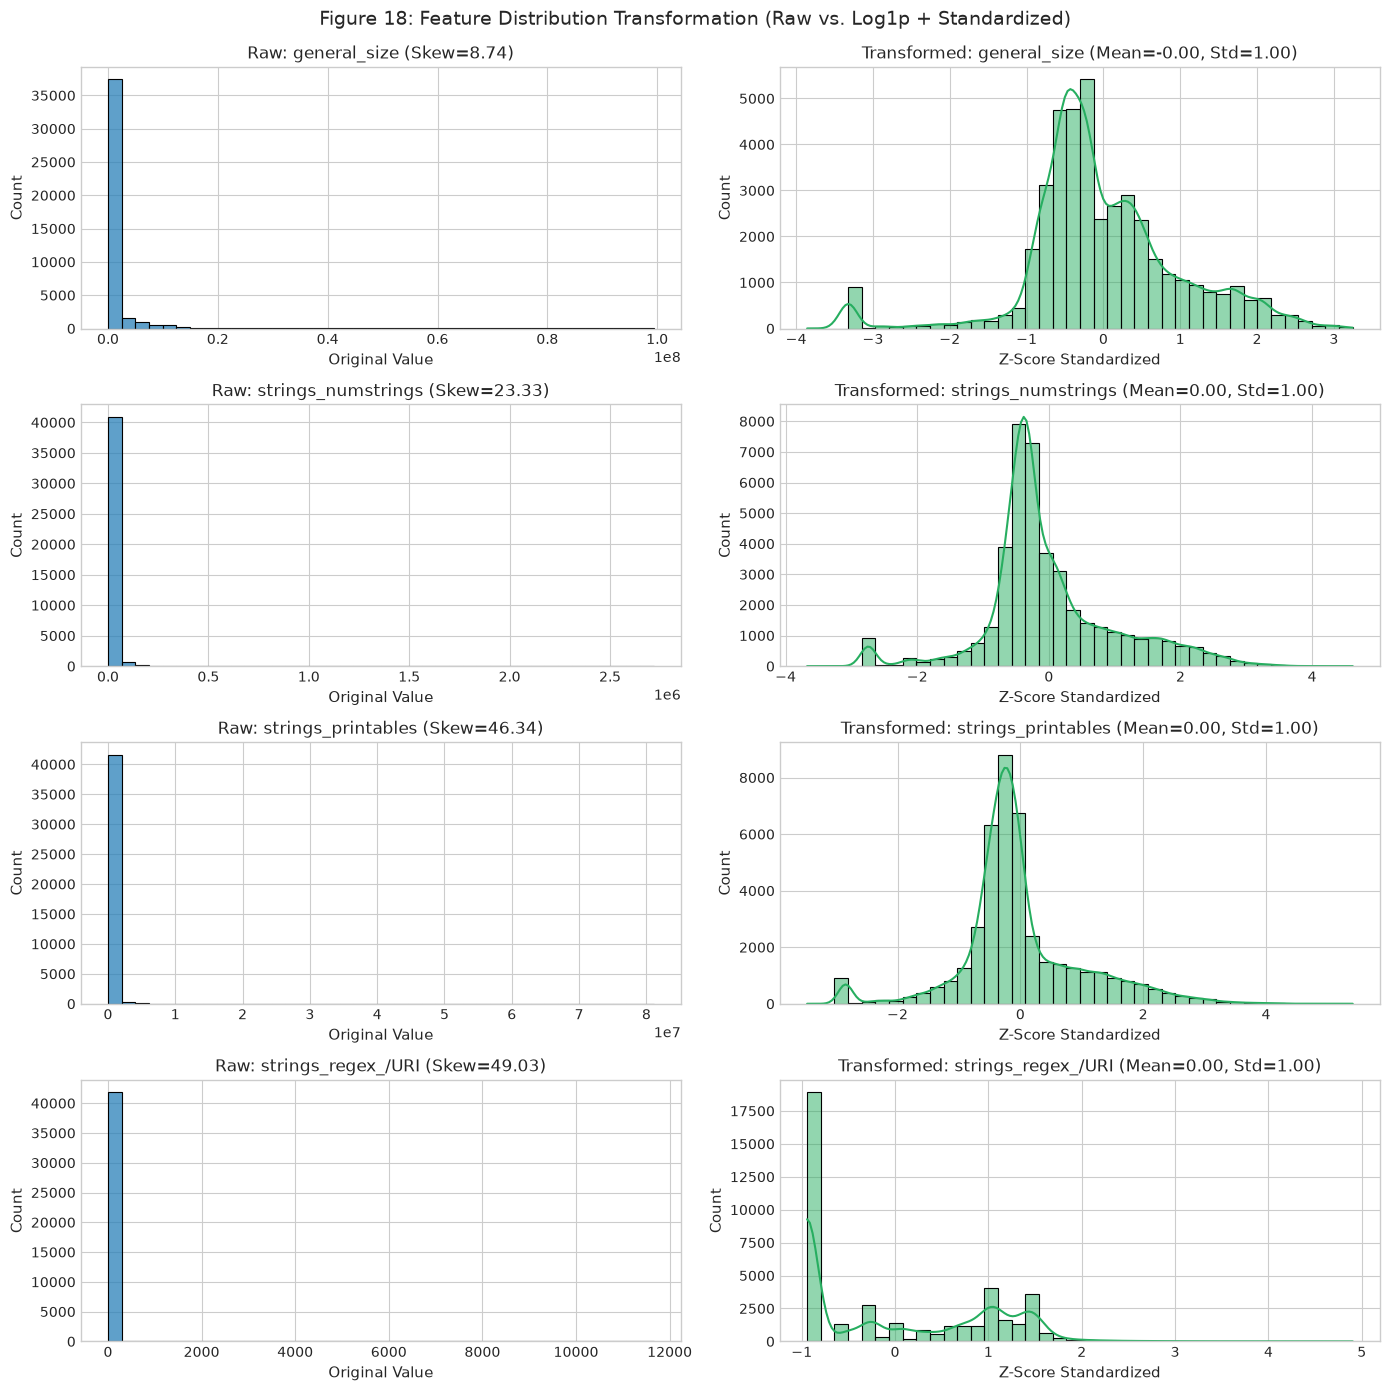

Saved Figure 18 to: ..\reports\figures\18_scaling_before_after.png


In [12]:
# Identify count and size features among kept_feature_names
count_size_keywords = {'general_size', 'strings_numstrings', 'strings_avlength', 'strings_printables'}
count_size_indices = [
    i for i, name in enumerate(kept_feature_names)
    if name in count_size_keywords or name.startswith('strings_regex_')
]

print(f"Identified {len(count_size_indices)} count/size features for log1p transformation.")

# Create Linear version: apply log1p to count/size features
X_tr_linear = X_tr_tree.copy()
X_va_linear = X_va_tree.copy()
X_te_linear = X_te_tree.copy()

X_tr_linear[:, count_size_indices] = np.log1p(np.maximum(0, X_tr_linear[:, count_size_indices]))
X_va_linear[:, count_size_indices] = np.log1p(np.maximum(0, X_va_linear[:, count_size_indices]))
X_te_linear[:, count_size_indices] = np.log1p(np.maximum(0, X_te_linear[:, count_size_indices]))

# Fit StandardScaler STRICTLY ON TRAIN ONLY
scaler = StandardScaler()
X_tr_linear = scaler.fit_transform(X_tr_linear)
X_va_linear = scaler.transform(X_va_linear)
X_te_linear = scaler.transform(X_te_linear)

# Verify zero leakage: train mean is 0, train var is 1
print("Scaler Verification:")
print(f"  Train transformed mean: {X_tr_linear.mean():.6f} (target ~ 0.0)")
print(f"  Train transformed var:  {X_tr_linear.var():.6f} (target ~ 1.0)")
print(f"  Val transformed mean:   {X_va_linear.mean():.6f}")
print(f"  Test transformed mean:  {X_te_linear.mean():.6f}")

# Plot Before / After distributions for 4 skewed features
fig_features = [
    'general_size',
    'strings_numstrings',
    'strings_printables',
    'strings_regex_/URI' if 'strings_regex_/URI' in kept_feature_names else kept_feature_names[count_size_indices[0]]
]

fig, axes = plt.subplots(4, 2, figsize=(14, 14))
fig.suptitle("Figure 18: Feature Distribution Transformation (Raw vs. Log1p + Standardized)", fontsize=14, y=0.99)

for row, feat_name in enumerate(fig_features):
    feat_idx = kept_feature_names.index(feat_name)
    
    # Raw distribution (Tree version)
    raw_vals = X_tr_tree[:, feat_idx]
    sns.histplot(raw_vals, bins=40, color='#2980b9', ax=axes[row, 0], kde=False)
    axes[row, 0].set_title(f"Raw: {feat_name} (Skew={stats.skew(raw_vals):.2f})")
    axes[row, 0].set_xlabel("Original Value")
    axes[row, 0].set_ylabel("Count")
    
    # Transformed distribution (Linear version)
    scaled_vals = X_tr_linear[:, feat_idx]
    sns.histplot(scaled_vals, bins=40, color='#27ae60', ax=axes[row, 1], kde=True)
    axes[row, 1].set_title(f"Transformed: {feat_name} (Mean={scaled_vals.mean():.2f}, Std={scaled_vals.std():.2f})")
    axes[row, 1].set_xlabel("Z-Score Standardized")
    axes[row, 1].set_ylabel("Count")

plt.tight_layout()
fig_path = FIGURES_DIR / "18_scaling_before_after.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Figure 18 to: {fig_path}")

---
# PART E: Data Serialization & Dimensionality Waterfall

In this section:
1. We serialize all partitioned matrices to high-performance Parquet format in `data/processed/`:
   - `X_train_tree.parquet`, `X_val_tree.parquet`, `X_test_tree.parquet`
   - `X_train_linear.parquet`, `X_val_linear.parquet`, `X_test_linear.parquet`
   - `y_train.parquet`, `y_val.parquet`, `y_test.parquet`
2. We serialize feature names (`feature_names.json`), fitted scaler (`scaler.joblib`), and comprehensive audit report (`preprocessing_report.json`).
3. We generate a waterfall-style chart tracking feature reduction from the original 696 candidates down to the final model inputs (`reports/figures/19_feature_reduction_waterfall.png`).

### 13. High-Performance Artifact Serialization
We convert matrices into DataFrames with ordered column names and write Parquet files alongside metadata artifacts.

In [13]:
# 1. Save Tree Version (Raw features)
df_X_tr_tree = pd.DataFrame(X_tr_tree, columns=kept_feature_names)
df_X_va_tree = pd.DataFrame(X_va_tree, columns=kept_feature_names)
df_X_te_tree = pd.DataFrame(X_te_tree, columns=kept_feature_names)

df_X_tr_tree.to_parquet(PROCESSED_DIR / 'X_train_tree.parquet', index=False)
df_X_va_tree.to_parquet(PROCESSED_DIR / 'X_val_tree.parquet', index=False)
df_X_te_tree.to_parquet(PROCESSED_DIR / 'X_test_tree.parquet', index=False)

# Also write standard X_train/X_val/X_test aliases for convenience
df_X_tr_tree.to_parquet(PROCESSED_DIR / 'X_train.parquet', index=False)
df_X_va_tree.to_parquet(PROCESSED_DIR / 'X_val.parquet', index=False)
df_X_te_tree.to_parquet(PROCESSED_DIR / 'X_test.parquet', index=False)

# 2. Save Linear Version (Log1p + Scaled features)
df_X_tr_linear = pd.DataFrame(X_tr_linear, columns=kept_feature_names)
df_X_va_linear = pd.DataFrame(X_va_linear, columns=kept_feature_names)
df_X_te_linear = pd.DataFrame(X_te_linear, columns=kept_feature_names)

df_X_tr_linear.to_parquet(PROCESSED_DIR / 'X_train_linear.parquet', index=False)
df_X_va_linear.to_parquet(PROCESSED_DIR / 'X_val_linear.parquet', index=False)
df_X_te_linear.to_parquet(PROCESSED_DIR / 'X_test_linear.parquet', index=False)

# 3. Save Targets
pd.DataFrame({'label': y_tr}).to_parquet(PROCESSED_DIR / 'y_train.parquet', index=False)
pd.DataFrame({'label': y_va}).to_parquet(PROCESSED_DIR / 'y_val.parquet', index=False)
pd.DataFrame({'label': y_te}).to_parquet(PROCESSED_DIR / 'y_test.parquet', index=False)

# 4. Save Ordered Feature Names
with open(PROCESSED_DIR / 'feature_names.json', 'w') as f:
    json.dump(kept_feature_names, f, indent=2)

# 5. Save Fitted Scaler
joblib.dump(scaler, PROCESSED_DIR / 'scaler.joblib')

# 6. Save Comprehensive Preprocessing Report
report_data = {
    'raw_candidate_features': 696,
    'dropped_constant_features': len(dropped_feature_names),
    'final_model_features': len(kept_feature_names),
    'splits': {
        'train': {
            'samples': len(y_tr),
            'benign': int((y_tr == 0).sum()),
            'malicious': int((y_tr == 1).sum()),
            'weeks': '0-41'
        },
        'validation': {
            'samples': len(y_va),
            'benign': int((y_va == 0).sum()),
            'malicious': int((y_va == 1).sum()),
            'weeks': '42-51',
            'tlsh_overlap_removed': len(val_leaks)
        },
        'test': {
            'samples': len(y_te),
            'benign': int((y_te == 0).sum()),
            'malicious': int((y_te == 1).sum()),
            'weeks': '52-63'
        }
    },
    'adversarial_drift_roc_auc': {
        'train_vs_val': float(round(auc_train_val, 4)),
        'train_vs_test': float(round(auc_train_test, 4))
    },
    'dropped_features_list': dropped_feature_names,
    'count_size_features_log1p': [kept_feature_names[i] for i in count_size_indices]
}

with open(PROCESSED_DIR / 'preprocessing_report.json', 'w') as f:
    json.dump(report_data, f, indent=2)

print("=" * 80)
print("PREPROCESSING ARTIFACTS SERIALIZED SUCCESSFULLY")
print("=" * 80)
for p in sorted(PROCESSED_DIR.glob('*')):
    size_mb = p.stat().st_size / (1024 * 1024)
    print(f"  {p.name:<32} {size_mb:>8.2f} MB")

PREPROCESSING ARTIFACTS SERIALIZED SUCCESSFULLY
  dedup_test.parquet                  12.60 MB
  dedup_train.parquet                 53.57 MB
  feature_names.json                   0.02 MB
  preprocessing_report.json            0.00 MB
  scaler.joblib                        0.02 MB
  X_test.parquet                      30.77 MB
  X_test_linear.parquet               30.77 MB
  X_test_tree.parquet                 30.77 MB
  X_train.parquet                    105.95 MB
  X_train_linear.parquet             105.94 MB
  X_train_tree.parquet               105.95 MB
  X_val.parquet                       26.00 MB
  X_val_linear.parquet                26.00 MB
  X_val_tree.parquet                  26.00 MB
  y_test.parquet                       0.00 MB
  y_train.parquet                      0.01 MB
  y_val.parquet                        0.00 MB


### 14. Dimensionality Waterfall Chart
We visualize the feature reduction lifecycle: from 696 candidate features across all four families down to the final 658 active model inputs.

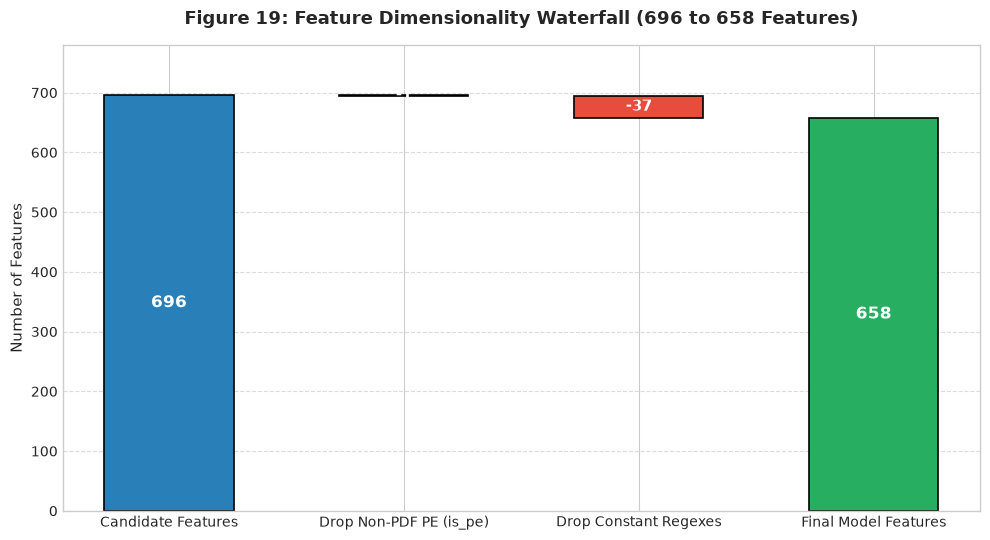

Saved Figure 19 to: ..\reports\figures\19_feature_reduction_waterfall.png


In [14]:
# Waterfall Chart Data
steps = [
    'Candidate Features',
    'Drop Non-PDF PE (is_pe)',
    'Drop Constant Regexes',
    'Final Model Features'
]

changes = [
    696,
    -1, # general_is_pe
    -(len(dropped_feature_names) - 1), # 37 constant regexes
    len(kept_feature_names)
]

cumulative = [696, 695, 658, 658]

fig, ax = plt.subplots(figsize=(10, 5.5))

colors = ['#2980b9', '#e74c3c', '#e74c3c', '#27ae60']
bottoms = [0, 695, 658, 0]
heights = [696, 1, len(dropped_feature_names) - 1, len(kept_feature_names)]

bars = ax.bar(steps, heights, bottom=bottoms, color=colors, edgecolor='black', linewidth=1.2, width=0.55)

# Value labels on bars
for i, bar in enumerate(bars):
    if i == 0 or i == 3:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2, f"{bar.get_height()}",
                ha='center', va='center', color='white', fontweight='bold', fontsize=12)
    else:
        ax.text(bar.get_x() + bar.get_width() / 2, bottoms[i] + heights[i] / 2, f"-{heights[i]}",
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

ax.set_ylim(0, 780)
ax.set_ylabel("Number of Features", fontsize=11)
ax.set_title("Figure 19: Feature Dimensionality Waterfall (696 to 658 Features)", fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
waterfall_path = FIGURES_DIR / "19_feature_reduction_waterfall.png"
plt.savefig(waterfall_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Figure 19 to: {waterfall_path}")